# Beavers, wildfire and vegetation: grid-cell statistics

Uses the tables made by the prep scripts (run from the `prep/` folder):

```
python prep_cells.py ..\NASAdata --land ..\site\public\geo_files\NA.geojson --cell-size 10 25 50 --out analysis_data
python animal_cells.py --grid analysis_data/50km analysis_data/25km analysis_data/10km --csv <gbif.csv> --label beaver --since 2015
```

Questions, all at the level of equal-area grid cells (North America Albers):

1. **Fire occurrence and extent:** do cells with beaver records burn less often, or less area, than similar cells without?
2. **Vegetation resistance:** in cells that burned, does greenness (NDVI) drop less where beavers are recorded?
3. **Robustness:** do the answers hold at 10, 25 and 50 km, and after accounting for spatial autocorrelation?

**Read before interpreting**
- GBIF records show where beavers were *observed*, not where they *live*: records cluster where people look. There is no effort correction here, so we use beaver **presence** (less sensitive to effort than counts), control for location and vegetation, and describe results as **associations**, not causes.
- Recovery after fire needs post-fire years; this notebook covers the fire season itself (resistance).
- If the MCD64A1 files are the synthetic samples, every burned-area number here is meaningless; rerun when the real data is in.

In [3]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## Settings

In [4]:
DATA = Path("analysis_data")
GRID = "50km"                    # main grid: "10km", "25km" or "50km"
GRIDS = ["10km", "25km", "50km"] # for the sensitivity check at the end
ANIMAL = "beaver"                # file name in analysis_data/<grid>/animals/

PRE_MONTH = "2026-06"            # NDVI before the fire season
POST_MONTH = "2026-09"           # NDVI after the fire season
FIRE_MONTHS = None               # None = every month that has burned-area data

MIN_LAND = 0.3                   # drop cells that are mostly ocean
MIN_VALID = 0.5                  # drop cells with too little valid NDVI (clouds, snow, water)
MIN_BURN_FRAC = 0.01             # a cell "burned" if >= 1% of its land burned (ignores specks)
LAT_BAND = 2                     # degrees: unburned cells in the same band give the normal seasonal NDVI change

## 1. Load and build one row per cell

From the monthly `panel.parquet`, each cell gets:
- `burned_frac`: share of the cell's land that burned in the fire months
- `ndvi_pre` / `ndvi_post`: NDVI before and after the fire season
- `ndvi_change_anom`: the cell's NDVI change **minus** the typical change of *unburned* cells at the same latitude. Vegetation browns in autumn everywhere; this keeps only the extra drop.
- `beaver_n` (records since 2015) and `beaver_present` (at least one record)

In [5]:
def load_cells(grid):
    d = DATA / grid
    meta = json.loads((d / "meta.json").read_text())
    panel = pd.read_parquet(d / "panel.parquet")
    cells = pd.read_parquet(d / "cells.parquet")
    animal = pd.read_parquet(d / "animals" / f"{ANIMAL}.parquet")[["cell_id", "n"]]

    fire_months = FIRE_MONTHS or meta["burn_months"]
    for m in (PRE_MONTH, POST_MONTH):
        if m not in meta["ndvi_months"]:
            raise ValueError(f"{m} has no NDVI in {grid}; available: {meta['ndvi_months']}")

    burn = (panel[panel["month"].isin(fire_months)]
            .groupby("cell_id")
            .agg(burned_km2=("burned_km2", "sum"), unmapped_frac=("unmapped_frac", "mean"),
                 first_burn_doy=("first_burn_doy", "min")))
    ndvi = panel.pivot(index="cell_id", columns="month", values="ndvi_mean")
    valid = panel.pivot(index="cell_id", columns="month", values="ndvi_valid_frac")

    df = (cells.merge(burn, on="cell_id", how="left")
               .merge(animal.rename(columns={"n": "beaver_n"}), on="cell_id", how="left"))
    df["beaver_n"] = df["beaver_n"].fillna(0).astype(int)
    df["beaver_present"] = (df["beaver_n"] > 0).astype(int)
    df["log_beaver"] = np.log1p(df["beaver_n"])
    df["ndvi_pre"] = df["cell_id"].map(ndvi[PRE_MONTH])
    df["ndvi_post"] = df["cell_id"].map(ndvi[POST_MONTH])
    df["ndvi_valid"] = np.fmin(df["cell_id"].map(valid[PRE_MONTH]), df["cell_id"].map(valid[POST_MONTH]))
    df["burned_frac"] = df["burned_km2"] / df["land_km2"]
    df["burned"] = (df["burned_frac"] >= MIN_BURN_FRAC).astype(int)

    df = df[(df["land_frac"] >= MIN_LAND) & (df["ndvi_valid"] >= MIN_VALID)].copy()
    df = df.dropna(subset=["burned_frac", "ndvi_pre", "ndvi_post"])

    # NDVI change relative to unburned cells at the same latitude
    df["ndvi_change"] = df["ndvi_post"] - df["ndvi_pre"]
    df["lat_band"] = (df["lat"] // LAT_BAND) * LAT_BAND
    normal = df[df["burned_frac"] == 0].groupby("lat_band")["ndvi_change"].median()
    df["ndvi_change_anom"] = df["ndvi_change"] - df["lat_band"].map(normal)
    df.attrs.update(grid=grid, fire_months=fire_months, meta=meta)
    return df


df = load_cells(GRID)
print(f"{GRID}: {len(df):,} cells | fire months {df.attrs['fire_months']} | "
      f"burned cells {df['burned'].sum():,} | cells with {ANIMAL} records {df['beaver_present'].sum():,}")
df.describe()[["land_km2", "burned_frac", "ndvi_pre", "ndvi_post", "ndvi_change_anom", "beaver_n"]].round(3)

50km: 7,902 cells | fire months ['2026-07', '2026-08'] | burned cells 244 | cells with beaver records 2,723


,land_km2,burned_frac,ndvi_pre,ndvi_post,ndvi_change_anom,beaver_n
count,7902.000,7902.000,7902.000,7902.000,7902.000,7902.000
mean,2452.033,0.002,0.555,0.553,-0.009,6.776
std,227.130,0.021,0.205,0.205,0.079,39.976
min,753.000,0.000,-0.110,-0.092,-0.523,0.000
25%,2500.000,0.000,0.440,0.410,-0.037,0.000
50%,2500.000,0.000,0.600,0.601,-0.002,0.000
75%,2500.000,0.000,0.706,0.719,0.030,2.000
max,2500.000,0.633,0.902,0.886,0.360,1657.000


## 2. Maps

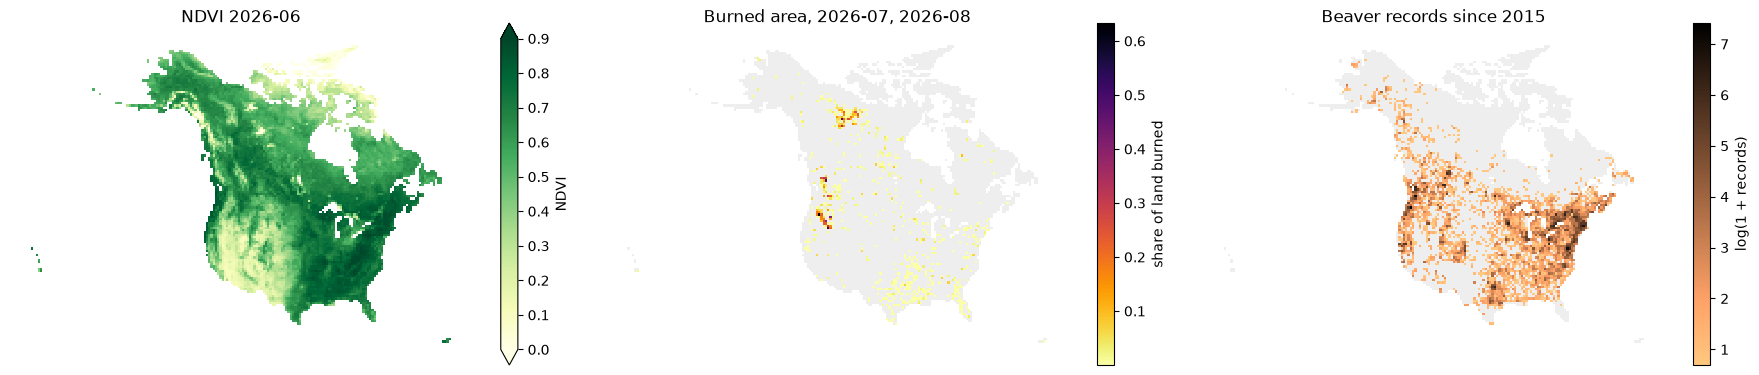

In [6]:
grid_geo = gpd.read_file(DATA / GRID / "grid.gpkg")[["cell_id", "geometry"]]
g = grid_geo.merge(df, on="cell_id")

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
g.plot(ax=ax[0], column="ndvi_pre", cmap="YlGn", vmin=0, vmax=0.9, legend=True,
       legend_kwds={"shrink": 0.6, "label": "NDVI"})
ax[0].set_title(f"NDVI {PRE_MONTH}")
g.plot(ax=ax[1], color="#eeeeee")
g[g["burned_frac"] > 0].plot(ax=ax[1], column="burned_frac", cmap="inferno_r", legend=True,
                             legend_kwds={"shrink": 0.6, "label": "share of land burned"})
ax[1].set_title(f"Burned area, {', '.join(df.attrs['fire_months'])}")
g.plot(ax=ax[2], color="#eeeeee")
g[g["beaver_n"] > 0].plot(ax=ax[2], column="log_beaver", cmap="copper_r", legend=True,
                          legend_kwds={"shrink": 0.6, "label": "log(1 + records)"})
ax[2].set_title(f"{ANIMAL.capitalize()} records since 2015")
for a in ax:
    a.set_axis_off()
plt.tight_layout()
plt.show()

## 3. Beavers and burned area

**3a. Spearman correlation.** Rank-based: no assumption of a straight line or normal data (most cells have 0 burned).

In [7]:
def spearman(x, y):
    r, p = stats.spearmanr(x, y)
    return round(r, 3), p

rows = {
    "all cells: beaver records vs burned share": spearman(df["log_beaver"], df["burned_frac"]),
    "burned cells only: beaver records vs burned share":
        spearman(df.loc[df["burned"] == 1, "log_beaver"], df.loc[df["burned"] == 1, "burned_frac"]),
}
pd.DataFrame(rows, index=["rho", "p"]).T

,rho,p
all cells: beaver records vs burned share,0.105,5.978781e-21
burned cells only: beaver records vs burned share,0.111,8.467553e-02


**3b. Two-part model.** "Did the cell burn?" and "how much burned?" are different questions:
- **Part 1** (logistic regression, all cells): `burned ~ beaver_present + ndvi_pre + lat + lon`
- **Part 2** (linear regression, burned cells only): `log(burned share) ~ beaver_present + ndvi_pre + lat + lon`

`ndvi_pre` controls for vegetation; `lat`/`lon` control for broad geography (climate, fire regime, where people observe).
An odds ratio below 1 means cells with beaver records were *less likely* to burn, all else equal.

In [8]:
def two_part(d):
    d = d.copy()
    for c in ("ndvi_pre", "lat", "lon"):
        d[c + "_z"] = (d[c] - d[c].mean()) / d[c].std()
    covars = "beaver_present + ndvi_pre_z + lat_z + lon_z"
    part1 = smf.logit(f"burned ~ {covars}", data=d).fit(disp=0, cov_type="HC3")
    b = d[d["burned"] == 1].assign(log_burn=lambda x: np.log(x["burned_frac"]))
    part2 = smf.ols(f"log_burn ~ {covars}", data=b).fit(cov_type="HC3") if len(b) >= 20 else None
    return part1, part2


part1, part2 = two_part(df)
ci = np.exp(part1.conf_int())
print("Part 1: did the cell burn?  (odds ratios, 95% CI)")
display(pd.DataFrame({"odds_ratio": np.exp(part1.params), "ci_low": ci[0], "ci_high": ci[1],
                      "p": part1.pvalues}).round(3))
if part2 is not None:
    ci2 = part2.conf_int()
    print("Part 2: how much burned (burned cells)?  exp(coef) = multiplicative change in burned share")
    display(pd.DataFrame({"times": np.exp(part2.params), "ci_low": np.exp(ci2[0]),
                          "ci_high": np.exp(ci2[1]), "p": part2.pvalues}).round(3))
else:
    print("Part 2 skipped: fewer than 20 burned cells")

Part 1: did the cell burn?  (odds ratios, 95% CI)


,odds_ratio,ci_low,ci_high,p
Intercept,0.026,0.021,0.031,0.000
beaver_present,1.480,1.083,2.021,0.014
ndvi_pre_z,1.136,0.997,1.295,0.055
lat_z,1.053,0.917,1.209,0.461
lon_z,0.699,0.633,0.772,0.000


Part 2: how much burned (burned cells)?  exp(coef) = multiplicative change in burned share


,times,ci_low,ci_high,p
Intercept,0.033,0.028,0.038,0.000
beaver_present,1.543,1.124,2.117,0.007
ndvi_pre_z,0.826,0.672,1.015,0.069
lat_z,1.084,0.898,1.309,0.400
lon_z,0.798,0.668,0.954,0.013


**3c. Spatial autocorrelation (Moran's I).** Neighbouring cells are alike, so the cells are not independent
and p-values above can be too small. Moran's I on the Part 1 residuals (8 neighbours per cell,
999 random shuffles) tells us how much that matters. I near 0 = fine; clearly positive = treat p-values with caution
and rely on the grid-size check in section 6.

In [9]:
def morans_i(values, rows, cols, permutations=999, seed=0):
    """Moran's I with queen (8-neighbour) weights on the grid, permutation p-value."""
    z = np.asarray(values, float) - np.mean(values)
    pos = {(r, c): i for i, (r, c) in enumerate(zip(rows, cols))}
    pairs = [(i, pos[(r + dr, c + dc)])
             for (r, c), i in pos.items()
             for dr in (-1, 0, 1) for dc in (-1, 0, 1)
             if (dr or dc) and (r + dr, c + dc) in pos]
    a, b = np.array(pairs).T
    stat = lambda v: len(v) / len(a) * np.sum(v[a] * v[b]) / np.sum(v * v)
    obs = stat(z)
    rng = np.random.default_rng(seed)
    sims = np.array([stat(rng.permutation(z)) for _ in range(permutations)])
    p = (np.sum(np.abs(sims) >= abs(obs)) + 1) / (permutations + 1)
    return obs, p


I, p = morans_i(part1.resid_pearson, df["row"], df["col"])
print(f"Moran's I of Part 1 residuals: {I:.3f} (p = {p:.3f})")

Moran's I of Part 1 residuals: 0.229 (p = 0.001)


## 4. Vegetation resistance: does NDVI drop less in burned cells with beavers?

For cells that burned, compare `ndvi_change_anom` (extra NDVI drop beyond the normal seasonal change)
between cells with and without beaver records. Fairfax & Whittle (2020) found NDVI dropped about 3x less
near beaver dams at the riparian scale; this checks for a landscape-scale signal.

burned cells: 244  (with beaver records: 101, without: 143)
median extra NDVI change  with: -0.048   without: -0.031   Mann-Whitney p = 0.0186


,coef,ci_low,ci_high,p
Intercept,0.0816,-0.0076,0.1709,0.0728
beaver_present,0.0010,-0.0310,0.0330,0.9499
burned_frac,-0.2135,-0.3056,-0.1213,0.0000
ndvi_pre,-0.1167,-0.1949,-0.0384,0.0035
lat,0.0011,-0.0004,0.0026,0.1470
lon,0.0009,0.0003,0.0015,0.0045


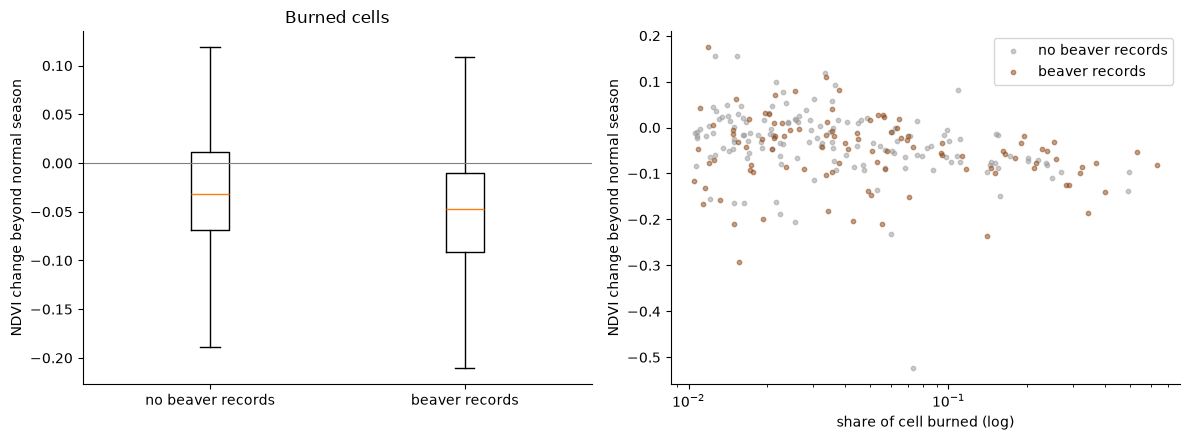

In [10]:
burned = df[df["burned"] == 1]
with_b = burned.loc[burned["beaver_present"] == 1, "ndvi_change_anom"]
without_b = burned.loc[burned["beaver_present"] == 0, "ndvi_change_anom"]
print(f"burned cells: {len(burned):,}  (with {ANIMAL} records: {len(with_b):,}, without: {len(without_b):,})")

if len(with_b) >= 5 and len(without_b) >= 5:
    u, p_mw = stats.mannwhitneyu(with_b, without_b, alternative="two-sided")
    print(f"median extra NDVI change  with: {with_b.median():+.3f}   without: {without_b.median():+.3f}   "
          f"Mann-Whitney p = {p_mw:.3g}")
    # bigger fires drop NDVI more, so compare at the same burned share
    m = smf.ols("ndvi_change_anom ~ beaver_present + burned_frac + ndvi_pre + lat + lon",
                data=burned).fit(cov_type="HC3")
    display(pd.DataFrame({"coef": m.params, "ci_low": m.conf_int()[0], "ci_high": m.conf_int()[1],
                          "p": m.pvalues}).round(4))

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].boxplot([without_b, with_b], showfliers=False)
    ax[0].set_xticks([1, 2], [f"no {ANIMAL} records", f"{ANIMAL} records"])
    ax[0].axhline(0, color="grey", lw=0.8)
    ax[0].set_ylabel("NDVI change beyond normal season")
    ax[0].set_title("Burned cells")
    for present, color in ((0, "#999999"), (1, "#8b4513")):
        s = burned[burned["beaver_present"] == present]
        ax[1].scatter(s["burned_frac"], s["ndvi_change_anom"], s=10, alpha=0.5, color=color,
                      label=f"{ANIMAL} records" if present else f"no {ANIMAL} records")
    ax[1].set_xscale("log")
    ax[1].set_xlabel("share of cell burned (log)")
    ax[1].set_ylabel("NDVI change beyond normal season")
    ax[1].legend()
    plt.tight_layout()
    plt.show()
else:
    print("Not enough burned cells in one of the groups for a comparison.")

## 5. Burned share by beaver presence

A simple picture for the presentation: among burned cells, how much of the cell burned, with and without beaver records.

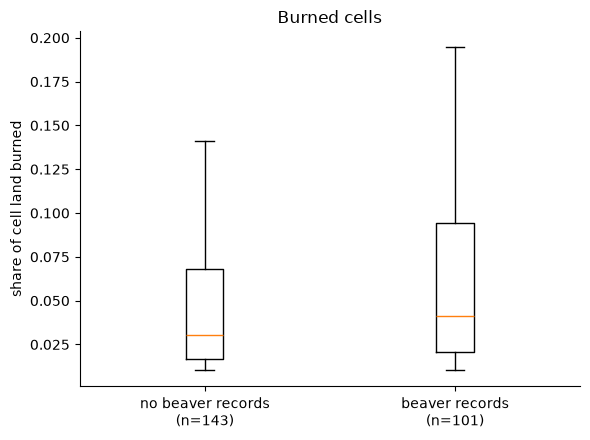

In [11]:
fig, ax = plt.subplots(figsize=(6, 4.5))
data = [burned.loc[burned["beaver_present"] == k, "burned_frac"] for k in (0, 1)]
ax.boxplot(data, showfliers=False)
ax.set_xticks([1, 2], [f"no {ANIMAL} records\n(n={len(data[0])})", f"{ANIMAL} records\n(n={len(data[1])})"])
ax.set_ylabel("share of cell land burned")
ax.set_title("Burned cells")
plt.tight_layout()
plt.show()

## 6. Does the answer depend on the grid size?

The same analysis at 10, 25 and 50 km. A relationship that keeps its direction at every size is far more
convincing than one that appears at a single size (the modifiable areal unit problem).

In [12]:
summary = []
for gname in GRIDS:
    try:
        d = load_cells(gname)
    except FileNotFoundError as e:
        print(f"skip {gname}: {e}")
        continue
    p1, p2 = two_part(d)
    rho, p_rho = spearman(d["log_beaver"], d["burned_frac"])
    b = d[d["burned"] == 1]
    res = {"grid": gname, "cells": len(d), "burned_cells": int(d["burned"].sum()),
           "cells_with_records": int(d["beaver_present"].sum()),
           "spearman_rho": rho, "spearman_p": p_rho,
           "burn_odds_ratio": np.exp(p1.params["beaver_present"]), "burn_or_p": p1.pvalues["beaver_present"]}
    if (b["beaver_present"] == 1).sum() >= 5 and (b["beaver_present"] == 0).sum() >= 5:
        m = smf.ols("ndvi_change_anom ~ beaver_present + burned_frac + ndvi_pre + lat + lon",
                    data=b).fit(cov_type="HC3")
        res.update(ndvi_effect=m.params["beaver_present"], ndvi_effect_p=m.pvalues["beaver_present"])
    summary.append(res)

pd.DataFrame(summary).round(4)

,grid,cells,burned_cells,cells_with_records,spearman_rho,spearman_p,burn_odds_ratio,burn_or_p,ndvi_effect,ndvi_effect_p
0,10km,194624,1812,11136,0.006,0.0122,1.1618,0.1227,0.0169,0.0146
1,25km,31336,576,5609,0.037,0.0000,1.1597,0.2022,0.0177,0.0505
2,50km,7902,244,2723,0.105,0.0000,1.4796,0.0138,0.0010,0.9499


## 7. NDVI timelapse (optional)

Mean NDVI per cell for every month, saved as a GIF. Built from `panel.parquet`, where pixels are assigned to
cells exactly; reprojecting with GDAL averaging is inaccurate far from the MODIS central meridian.

In [13]:
from PIL import Image
import io

panel = pd.read_parquet(DATA / GRID / "panel.parquet")
months = sorted(panel.loc[panel["ndvi_mean"].notna(), "month"].unique())
frames = []
for m in months:
    gm = grid_geo.merge(panel[panel["month"] == m][["cell_id", "ndvi_mean"]], on="cell_id")
    fig, ax = plt.subplots(figsize=(9, 7))
    gm.plot(ax=ax, column="ndvi_mean", cmap="YlGn", vmin=0, vmax=0.9, legend=True,
            legend_kwds={"shrink": 0.6, "label": "NDVI"}, missing_kwds={"color": "#f2f2f2"})
    ax.set_title(f"Mean NDVI per {GRID} cell, {m}")
    ax.set_axis_off()
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=80, facecolor="white")
    plt.close(fig)
    frames.append(Image.open(buf).convert("RGB"))
frames[0].save(f"ndvi_timelapse_{GRID}.gif", save_all=True, append_images=frames[1:], duration=900, loop=0)
print(f"saved ndvi_timelapse_{GRID}.gif ({len(frames)} months)")

saved ndvi_timelapse_50km.gif (7 months)


## 8. Writing it up

- Report the **odds ratio** (Part 1), the **burned-share ratio** (Part 2) and the **NDVI effect** (section 4) with 95% CIs, at each grid size.
- Report Moran's I; if residuals are clearly autocorrelated, say p-values are optimistic and lean on consistency across grid sizes.
- Wording: *"Cells with beaver records burned X% less often, after accounting for vegetation and location"*, not *"beavers reduce fire"*.
- Limitations: GBIF observation bias (no effort correction), 1 km NDVI mixes riparian strips with surrounding forest, MCD64A1 misses small fires, a single season of data.